# Degree Correlations

Emma K. Towlson with Sean P. Cornelius and Albert-László Barabási

Let's retrieve some of our code from earlier:
* Import the desired modules
* Tidy up the figure settings
* Functions to generate E-R networks ($G(n,p)$ model), and scale-free networks (configuration model)

In [92]:
import numpy as np
import random
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib as mpl
%matplotlib inline

In [93]:
# change defaults to be less ugly
mpl.rc('xtick', labelsize=14, color="#222222") 
mpl.rc('ytick', labelsize=14, color="#222222") 
mpl.rc('font', **{'family':'sans-serif','sans-serif':['Arial']})
mpl.rc('font', size=16)
mpl.rc('xtick.major', size=6, width=1)
mpl.rc('xtick.minor', size=3, width=1)
mpl.rc('ytick.major', size=6, width=1)
mpl.rc('ytick.minor', size=3, width=1)
mpl.rc('axes', linewidth=1, edgecolor="#222222", labelcolor="#222222")
mpl.rc('text', usetex=False, color="#222222")

In [94]:
def erdos_renyi(n, p):
    # Create an empty graph
    G = nx.Graph()
    
    # add nodes (integers between zero and n-1)
    G.add_nodes_from(range(0, n))
    
    # for all possible pairs of nodes, add a link with probability p
    for node1 in range(0, n):
        for node2 in xrange(node1 + 1, n):
            if np.random.uniform() < p:
                G.add_edge(node1, node2)
    return G

In [95]:
def powerlaw_degree_sequence(n, gamma, k_min):
    """ Implements the method for generating power-law distributed numbers
    from uniformly-distributed numbers described in Clauset et al., 2009,
    appendix D"""
    r = np.random.uniform(0, 1, size=n)
    deg = np.floor((k_min-0.5)*(1.0 - r)**(-1.0/(gamma-1)) + 0.5)
    deg = list(map(int, deg))
    return deg

def sf_net(n,  gamma, k_min):
    deg = powerlaw_degree_sequence(n, gamma, k_min)
    # sum of all degrees must be even. Why is that?
    if sum(deg) % 2 == 1:
        deg[0] += 1
    G = nx.configuration_model(deg)
    H = nx.Graph(G)
    H.remove_edges_from(H.selfloop_edges())
    return H

# Degree Correlations in NetworkX

Recall we discussed 3 approaches to examining degree correlations:
* Statistical description
* Degree correlation function (average nearest neighbour degree)
* Degree assortativity coefficient

In [96]:
# Generate an E-R random graph
G = erdos_renyi(10**4, 1e-3)

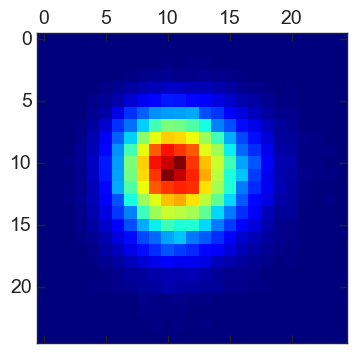

In [97]:
# 1. the matrix e_ij
M = nx.degree_mixing_matrix(G)
plt.matshow(M)

In [98]:
# 2. Average nearest neighbour degree

k = list(nx.degree(G).values())
k_ann = list(nx.average_neighbor_degree(G).values())

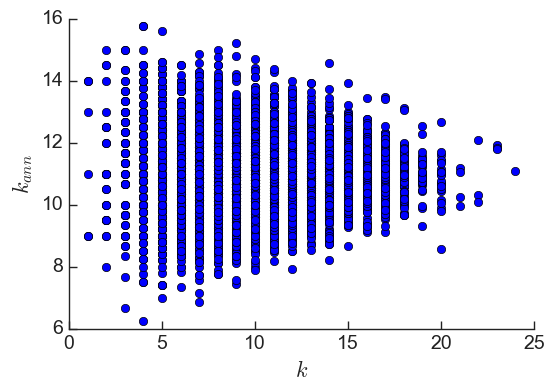

In [99]:
plt.plot(k,k_ann,marker='o', linestyle='none')
plt.xlabel(r"$k$",fontsize=16)
plt.ylabel(r"$k_{ann}$",fontsize=16)

# remove right and top boundaries because they're ugly
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom')

In [100]:
def linear_bins(G,num_bins):

    # Linearly bin the degrees between kmin and kmax

    kmin = min(k)
    kmax = max(k)+1
    bin_edges = np.linspace(kmin, kmax, num=num_bins+1)

    # Average k_ann within bins

    inds = np.digitize(k, bin_edges)
    bin_k_ann = {}
    for be in range(num_bins):
        bin_k_ann[be] = []
    for i in range(len(k_ann)):
        curr_bin = inds[i]-1
        bin_k_ann[curr_bin].append(k_ann[i])
    k_ann_means = []
    for be in range(num_bins):
        k_ann_means.append(np.mean(bin_k_ann[be]))

    # "x" should be midpoint of each bin
    x = (bin_edges[1:] + bin_edges[:-1])/2
    
    return x, k_ann_means


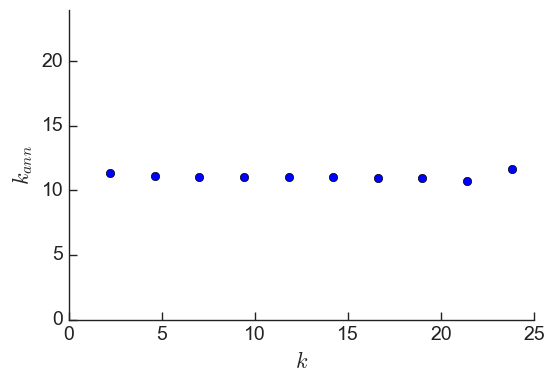

In [101]:
x,k_ann_means = linear_bins(G,10)

plt.plot(x,k_ann_means,marker='o',linestyle='none',color='b')

# remove right and top boundaries because they're ugly
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom')
# fix limits and label
kmax = max(nx.degree(G).values())
ax.set_ylim([0,kmax])
plt.xlabel(r"$k$",fontsize=16)
plt.ylabel(r"$k_{ann}$",fontsize=16)


In [102]:
# Should you want to bin logarithmically... (Hint: you don't now but you do later)

def log_bins_kann(G,num_bins):
    
    k = list(nx.degree(G).values())
    k_ann = list(nx.average_neighbor_degree(G).values())

    # Logarithmically bin the data between kmin and kmax
    kmin = min(k)
    kmax = max(k)+1
    bin_edges = np.logspace(np.log10(kmin), np.log10(kmax), num=num_bins+1)


    # Average k_ann within bins

    inds = np.digitize(k, bin_edges)
    bin_k_ann = {}
    for be in range(num_bins):
        bin_k_ann[be] = []
    for i in range(len(k_ann)):
        curr_bin = inds[i]-1
        bin_k_ann[curr_bin].append(k_ann[i])
    k_ann_means = []
    for be in range(num_bins):
        k_ann_means.append(np.mean(bin_k_ann[be]))


    # "x" should be midpoint (IN LOG SPACE) of each bin
    log_be = np.log10(bin_edges)
    x = 10**((log_be[1:] + log_be[:-1])/2)
    
    return x, k_ann_means



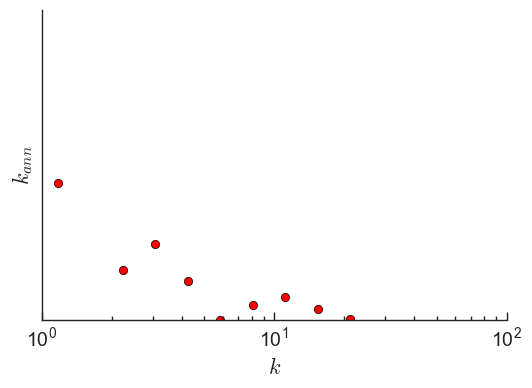

In [103]:
x,k_ann_means = log_bins_kann(G,10)
plt.loglog(x,k_ann_means,marker='o',linestyle='none',color='r')


# remove right and top boundaries because they're ugly
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom')

# fix limits and label
ax.set_ylim([0,max(k_ann_means)+1])
plt.xlabel(r"$k$",fontsize=16)
plt.ylabel(r"$k_{ann}$",fontsize=16)

In [104]:
# 3. Degree assortativity coefficient
nx.degree_assortativity_coefficient(G)

-0.002967053013162432

# Structural Disassortativity



## Exercise

Split into five groups. Each group should generate scale-free networks with the functions above, and examine:
* $E_{ij}$
* Average nearest neaighbour degree
* Degree correlation coefficient

Discuss your results - what do you expect to see?

Each network should be generated with $k_{min}=5$ and $N=10**4$. Then:
1. $\gamma = 2.1$
2. $\gamma = 2.9$
3. $\gamma = 3$
4. $\gamma = 4$
5. You know what is going to happen - can you stop it? (Demonstrate!)



# The importance of null models

In [105]:
G = sf_net(10**3, 2.4, 5)

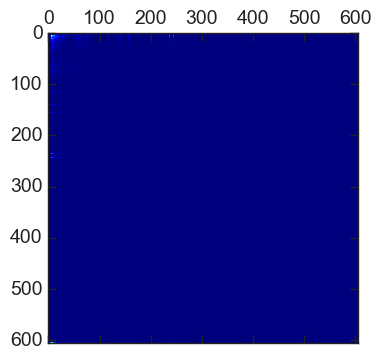

In [106]:
M = nx.degree_mixing_matrix(G)
plt.matshow(M)

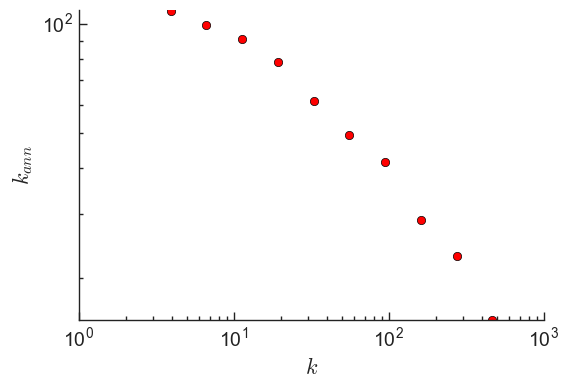

In [107]:
x, k_ann_means = log_bins_kann(G,10)

plt.loglog(x,k_ann_means,marker='o',linestyle='none',color='r')


# remove right and top boundaries because they're ugly
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom')

# fix limits and label
ax.set_ylim([0,max(k_ann_means)+1])
plt.xlabel(r"$k$",fontsize=16)
plt.ylabel(r"$k_{ann}$",fontsize=16)

In [108]:
nx.degree_assortativity_coefficient(G)

-0.15619091558912432

In [ ]:
# Is it "real"? We need to check against a randomised network with the same degree sequence. 

In [109]:
def simple_randomisation(G,nswaps):
    
    H = G.copy()
    # Swap nswaps edges in the graph - modifies in place
    # Adds connectivity constraint, and disallows multiple edges
    nx.connected_double_edge_swap(H, nswap=nswaps)
    
    return H

In [110]:
H = simple_randomisation(G,10**3)

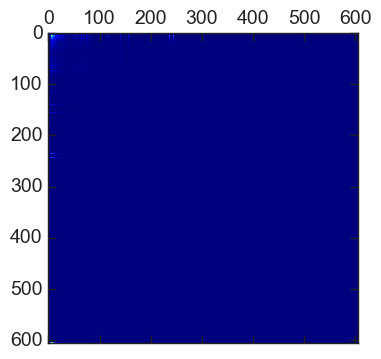

In [111]:
M_R = nx.degree_mixing_matrix(H)
plt.matshow(M_R)

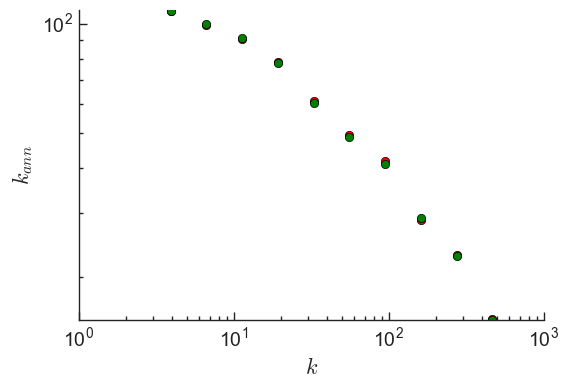

In [112]:
# Plot the same figure, but with the randomised version also
# Note: this is VERY BAD practice!! You should never rely on only one instance of a randomised network - create 
# an ensemble.

# Data:
x, k_ann_means = log_bins_kann(G,10)
plt.loglog(x,k_ann_means,marker='o',linestyle='none',color='r')

# Randomised:

x_r, k_ann_means_r = log_bins_kann(H,10)
plt.loglog(x_r,k_ann_means_r,marker='o',linestyle='none',color='g')

# Settings:
# remove right and top boundaries because they're ugly
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom')

# fix limits and label
ax.set_ylim([0,max(k_ann_means)+1])
plt.xlabel(r"$k$",fontsize=16)
plt.ylabel(r"$k_{ann}$",fontsize=16)

In [ ]:
nx.degree_assortativity_coefficient(H)

## Exercise

You have 4 real-world networks. So split into 4 groups - but each individual should have at a go at this.

* Investigate the mixing matrices
* Plot $k$ against $k_{ann}$ (choose linear or log scales as appropriate for the data)
* Calculate the degree assortativity coefficient

...for each network AND a randomised counterpart.

Can you guess which is which? They contain (in some order):
* A network of dependencies between libraries in VTK
* The C. elegans neuronal network
* A co-authorship network in the area of General Relativity
* An projected network of Paul Revere and his compatriots